In [3]:
# imports

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from pathlib import Path


# Bernoulli model
Estimate gene family prevalences (pi values) from incomplete genomes based on a 
Bernoulli model

In [4]:
# function to estimate gene family prevalence using a Bernoulli model

def estimate_prevalence_bernoulli(data, lambdas):
    """
    Estimate gene family prevalence using a Bernoulli model.
    
    Parameters:
    data (pd.DataFrame): A DataFrame containing presence/absence data for gene families across genomes.
    lambdas (pd.Series): A series of lambda values corresponding to the completeness of each genome
        in the dataset, with values between 0 and 1.
    
    Returns:
    pd.Series: A series of pi values representing the estimated prevalence of each gene family.
    """
    # Ensure that the index of lambdas matches the columns of data
    if not all(lambdas.index == data.columns):
        raise ValueError("The index of lambdas must match the columns of data.")
    
    # Ensure the presence/absence data is binary (0 and 1)
    data = data.astype(int)  # Convert to integer type if not already
    if not data.map(lambda x: x in [0, 1]).all().all():
        raise ValueError("Data must be binary (0 and 1).")
    
    # Calculate inverse of the lambda values
    inverse_lambdas = 1 / lambdas

    # Multiply the presence/absence data by the inverse of the lambda values
    weighted_data = data.multiply(inverse_lambdas, axis=1)

    # Estimate the prevalence (pi) for each gene family as the expected value of the weighted presence/absence data
    pi_estimates = weighted_data.mean(axis=1)
    
    return pi_estimates

# Simulated Data
Evaluate model using simulated data
- Uniform missingness
- Systematic missingness
- Systematic missingness due to multicopy genes

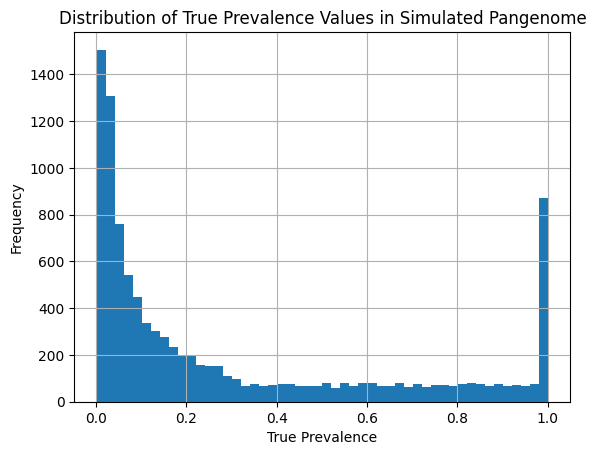

In [21]:
# read in simulated pangenome data

sim_data_dir = Path('../data/simulated')

# simulated presence/absence data
sim_pangenome_df = pd.read_csv(
    sim_data_dir / 'simulated_presence_absence_complete.csv', index_col=0)
sim_incomplete_df = pd.read_csv(
    sim_data_dir / 'simulated_presence_absence_incomplete.csv', index_col=0)
sim_incomplete_biased_df = pd.read_csv(
    sim_data_dir / 'simulated_presence_absence_incomplete_biased.csv', index_col=0)
sim_incomplete_count_df = pd.read_csv(
    sim_data_dir / 'simulated_presence_absence_incomplete_from_count.csv', index_col=0)

# simulated genome completeness values
sim_completeness = pd.read_csv(
    sim_data_dir / 'simulated_genome_completeness_levels.csv', index_col=0)['Completeness']

# simulated detection bias values
sim_detection_bias = pd.read_csv(
    sim_data_dir / 'simulated_gene_detection_bias_values.csv', index_col=0)['Detection_Bias']

# simulated gene count per genome data
sim_mean_gene_count_df = pd.read_csv(
    sim_data_dir / 'simulated_mean_gene_counts_when_present.csv', index_col=0)['Mean_Gene_Count_When_Present']

# calculate ground truth prevalence values for simulated data using complete presence/absence data
ground_truth = sim_pangenome_df.mean(axis=1)
ground_truth.hist(bins=50)
plt.xlabel('True Prevalence')
plt.ylabel('Frequency')
plt.title('Distribution of True Prevalence Values in Simulated Pangenome')
plt.show()


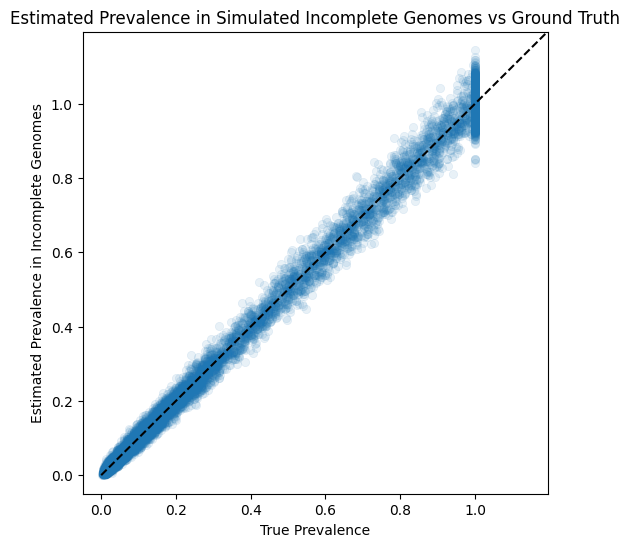

In [9]:
# run Bernoulli model on simulated data with uniform missingness

lambdas_incomplete = estimate_prevalence_bernoulli(
    data=sim_incomplete_df,
    lambdas=sim_completeness.loc[sim_incomplete_df.columns]
)

# Create a scatter plot
plt.figure(figsize=(6, 6))
sns.scatterplot(x=ground_truth, y=lambdas_incomplete, alpha=0.1, edgecolor=None)

# Add a line for perfect agreement
plt.plot([0, 100], [0, 100], '--', color='black')  # Line with slope 1

# Set ranges for x and y axes
maximum = max(ground_truth.max(), lambdas_incomplete.max())
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# Set labels and title
plt.xlabel('True Prevalence')
plt.ylabel('Estimated Prevalence in Incomplete Genomes')
plt.title('Estimated Prevalence in Simulated Incomplete Genomes vs Ground Truth')
plt.show()


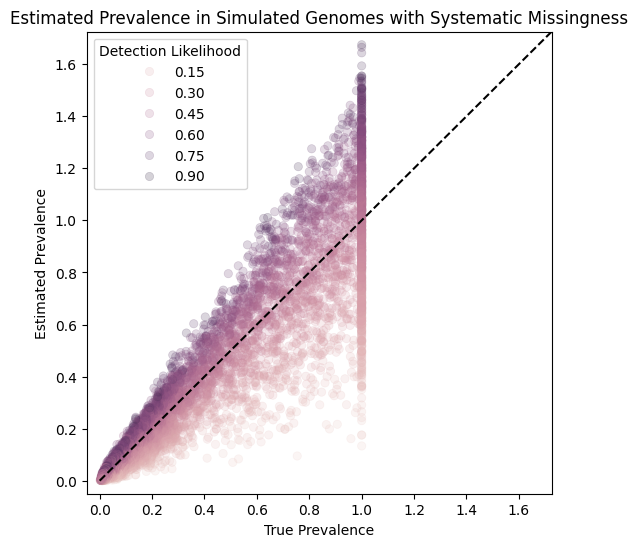

In [16]:
# run Bernoulli model on simulated data with biased missingness

lambdas_incomplete = estimate_prevalence_bernoulli(
    data=sim_incomplete_biased_df,
    lambdas=sim_completeness.loc[sim_incomplete_biased_df.columns]
)

# Create a scatter plot
plt.figure(figsize=(6, 6))
sns.scatterplot(
    x=ground_truth, 
    y=lambdas_incomplete, 
    hue=sim_detection_bias.loc[sim_incomplete_biased_df.index],
    alpha=0.2, 
    edgecolor=None)

# Add a line for perfect agreement
plt.plot([0, 100], [0, 100], '--', color='black')  # Line with slope 1

# Set ranges for x and y axes
maximum = max(ground_truth.max(), lambdas_incomplete.max())
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# Set labels and title
plt.xlabel('True Prevalence')
plt.ylabel('Estimated Prevalence')
plt.title('Estimated Prevalence in Simulated Genomes with Systematic Missingness')
plt.legend(title='Detection Likelihood')

# Show the plot
plt.show()

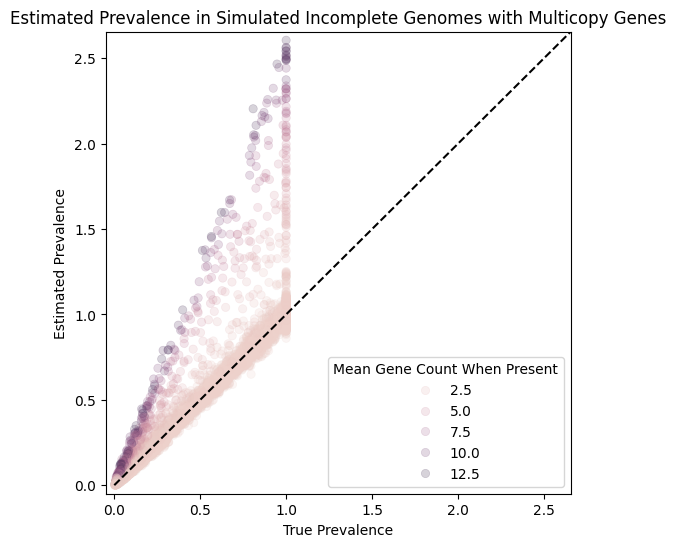

In [22]:
# run Bernoulli model on incomplete simulated data created using multicopy gene counts

lambdas_incomplete = estimate_prevalence_bernoulli(
    data=sim_incomplete_count_df,
    lambdas=sim_completeness.loc[sim_incomplete_count_df.columns]
)

# Create a scatter plot
plt.figure(figsize=(6, 6))
sns.scatterplot(
    x=ground_truth, 
    y=lambdas_incomplete, 
    hue=sim_mean_gene_count_df.loc[sim_incomplete_count_df.index],
    alpha=0.2, 
    edgecolor=None)

# Add a line for perfect agreement
plt.plot([0, 100], [0, 100], '--', color='black')  # Line with slope 1

# Set ranges for x and y axes
maximum = max(ground_truth.max(), lambdas_incomplete.max())
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# Set labels and title
plt.xlabel('True Prevalence')
plt.ylabel('Estimated Prevalence')
plt.title('Estimated Prevalence in Simulated Incomplete Genomes with Multicopy Genes')
plt.legend(title='Mean Gene Count When Present')

# Show the plot
plt.show()

# Real data
Evaluate model using real data

In [ ]:
# read in HLII presence/absence data

hlii_complete_df = pd.read_csv('../data/subsets/hlii_presence_absence_data_complete.csv', index_col=0)
hlii_incomplete_df = pd.read_csv('../data/subsets/hlii_presence_absence_data_incomplete.csv', index_col=0)
genome_metadata_df = pd.read_csv('../data/pro_pangenome_metadata.csv')
completeness_series = genome_metadata_df.set_index('genome')['completeness'] / 100

hlii_complete_df

In [ ]:
# plot pi estimates against ground truth prevalence values

# calculate pi estimates for incomplete genomes
lambdas_incomplete = estimate_prevalence_bernoulli(
    data=hlii_incomplete_df, 
    lambdas=completeness_series.loc[hlii_incomplete_df.columns]
)

# calculate ground truth prevalence values from complete genomes
ground_truth = hlii_complete_df.mean(axis=1)

# Create a scatter plot
plt.figure(figsize=(6, 6))
sns.scatterplot(x=ground_truth, y=lambdas_incomplete, alpha=0.2, edgecolor=None)

# Add a line for perfect agreement
plt.plot([0, 1], [0, 1], '--', color='gray')  # Line with slope 1

# Set ranges for x and y axes
maximum = max(ground_truth.max(), lambdas_incomplete.max())
plt.xlim(-0.05, maximum + 0.05)
plt.ylim(-0.05, maximum + 0.05)

# Set labels and title
plt.xlabel('Prevalence in Complete Genomes')
plt.ylabel('Estimated Prevalence in Incomplete Genomes')
plt.title('Estimated Prevalence in Complete vs Incomplete HLII Pro Genomes')

# Show the plot
# plt.grid()
plt.show()

In [ ]:
# evaluate estimator statistics 

residuals = ground_truth - lambdas_incomplete
mse = np.mean(residuals ** 2)
rmse =  np.sqrt(mse)

print(f'MSE: {mse:.4f}')
print(f'RMSE: {rmse:.4f}')